<a href="https://colab.research.google.com/github/sethkipsangmutuba/Computer-Graphics-Animation/blob/main/A1_COMP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **INTRODUCTION TO COMPUTER GRAPHICS & ANIMATION**

##Seth Kipsang

## **1.0 Introduction**

Computer graphics is the mathematical and computational discipline concerned with creating, manipulating, analysing and displaying visual information. It encompasses two-dimensional (2D) and three-dimensional (3D) representations, synthetic environments, image processing and computer-generated animation. Its foundations integrate geometry, linear algebra, numerical analysis, computational algorithms and physical modelling to achieve accurate and efficient visual representations.

## **1.1 Major Areas of Computer Graphics**

Computer graphics comprises three principal areas:

1. **Modelling:** Mathematical representation of an object's geometry, topology and appearance. A three-dimensional object can be represented by vertices $P_i=(x_i,y_i,z_i)$, connected to form polygonal surfaces and associated with material properties.

2. **Rendering:** Conversion of geometric models into images through projection, illumination, shading and light-transport calculations.

3. **Animation:** Mathematical representation of temporal changes in position, orientation and shape. An object's trajectory is expressed as $P(t)=(x(t),y(t),z(t))$, where $t$ denotes time.

Related disciplines include virtual reality, interactive graphics, scientific visualisation, image processing, computational photography and three-dimensional scanning.

## **1.2 Applications**

Computer graphics supports video games, animated films, visual effects, computer-aided design and manufacturing (CAD/CAM), medical imaging, engineering simulation and information visualisation. These applications employ computational geometry, image synthesis and mathematical modelling to represent complex physical and conceptual environments.

## **1.3 Graphics Application Programming Interfaces**

Graphics application programming interfaces (APIs) provide standardized mechanisms for communicating graphical operations to hardware. OpenGL supports cross-platform graphics rendering, whereas GLUT supplies utility functions for window management and interaction. Microsoft Foundation Classes (MFC) provides Windows application-interface infrastructure rather than a dedicated rendering API. These technologies differ in portability, functionality and platform dependence.

## **1.4 The Graphics Pipeline**

The graphics pipeline converts three-dimensional geometric descriptions into two-dimensional screen images. Homogeneous coordinates represent a spatial point as

$$
P=\begin{bmatrix}x&y&z&w\end{bmatrix}^{T}.
$$

Geometric transformations are performed using

$$
P'=MP,
$$

where $M\in\mathbb{R}^{4\times4}$ is a transformation matrix. The pipeline comprises modelling, viewing, projection, clipping, rasterisation and fragment shading. Depth-buffering (Z-buffering) resolves visibility by comparing competing fragment depths.


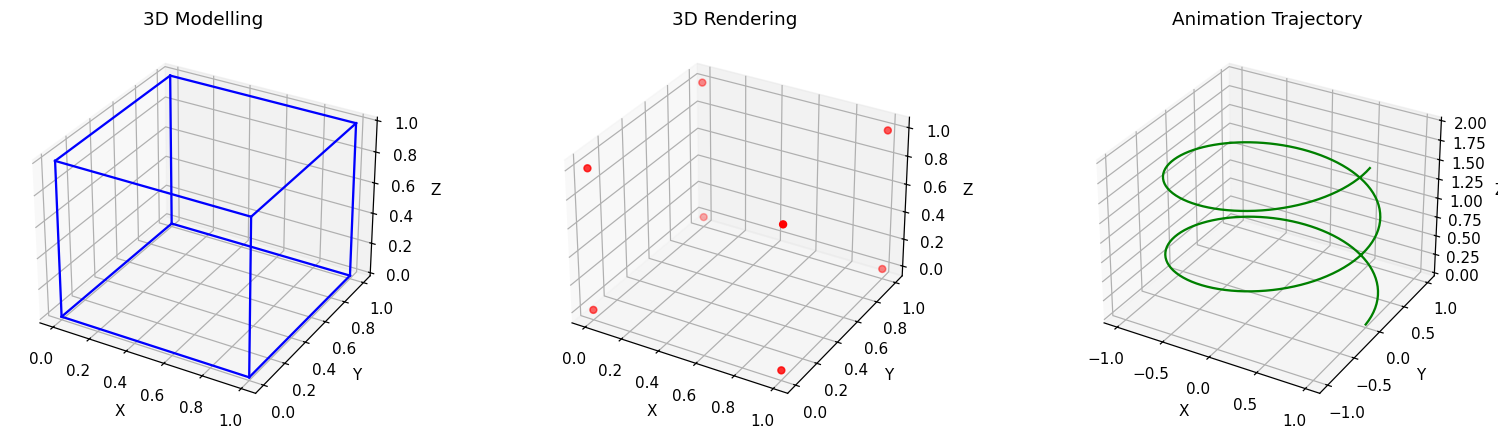

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 3D cube vertices
vertices = np.array([
    [0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],
    [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]
])

edges = [
    (0,1), (1,2), (2,3), (3,0),
    (4,5), (5,6), (6,7), (7,4),
    (0,4), (1,5), (2,6), (3,7)
]

# Animation trajectory
t = np.linspace(0, 4*np.pi, 200)
x = np.cos(t)
y = np.sin(t)
z = t / (2*np.pi)

# Three subplots in one row
fig = plt.figure(figsize=(15, 4))

# 1. Modelling
ax1 = fig.add_subplot(131, projection='3d')
for i, j in edges:
    ax1.plot(*vertices[[i, j]].T, color='blue')
ax1.set_title("3D Modelling")

# 2. Rendering
ax2 = fig.add_subplot(132, projection='3d')
ax2.scatter(*vertices.T, color='red')
ax2.set_title("3D Rendering")

# 3. Animation
ax3 = fig.add_subplot(133, projection='3d')
ax3.plot(x, y, z, color='green')
ax3.set_title("Animation Trajectory")

for ax in (ax1, ax2, ax3):
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

plt.tight_layout()
plt.show()


## **1.5 Numerical Issues**

Graphics calculations employ floating-point arithmetic, commonly conforming to IEEE 754. Numerical systems represent finite values, signed zeros, infinities and NaN (Not a Number). For example,

$$
\frac{0}{0}=NaN,\qquad \infty-\infty=NaN.
$$

Comparisons involving NaN evaluate as false. These properties affect geometric transformations, projection and illumination. Numerical stability, precision and error propagation must therefore be controlled to preserve computational reliability.

## **1.6 Computational Efficiency**

Computational efficiency measures the processing time and memory resources required to produce graphical results. Performance depends on algorithmic complexity, processor architecture, memory locality and data organization. Level of Detail (LOD) reduces geometric complexity for distant objects, balancing visual fidelity and computational cost.

Effective optimisation involves algorithmic refinement, profiling, compiler optimisation and improved memory access. Decisions should be evidence-based because unnecessary optimisation can compromise accuracy and maintainability.



Numerical Results: [np.float64(nan) np.float64(nan) np.False_ np.float64(1.0)]
NaN comparison: False
Finite values: [ True False False  True]


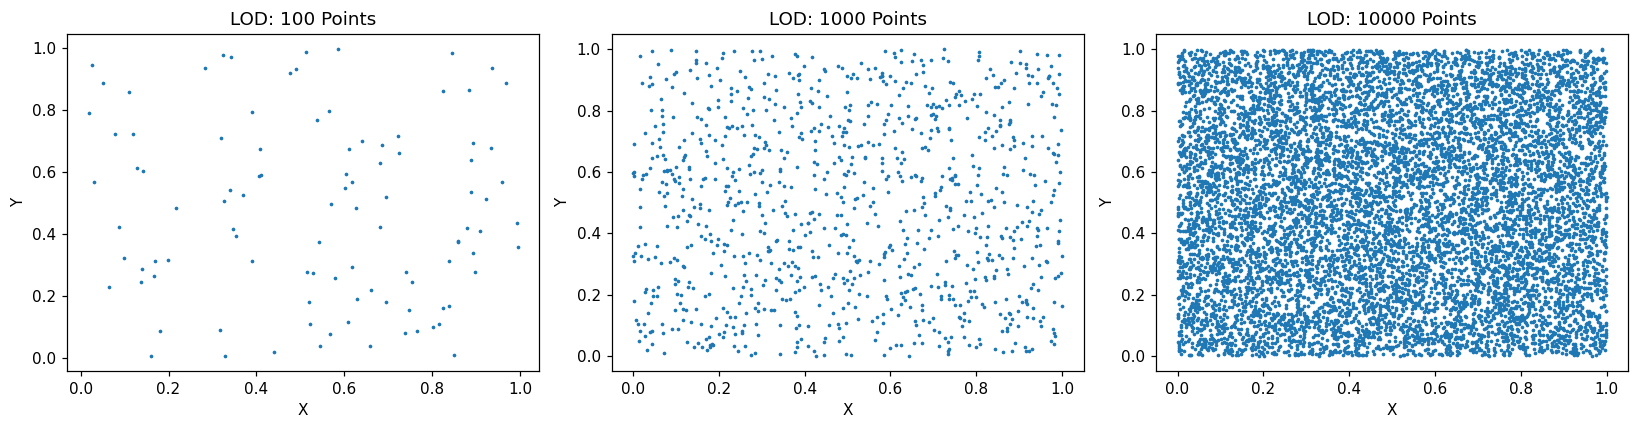

100 points: 0.000314 seconds
1000 points: 0.000058 seconds
10000 points: 0.000415 seconds


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import time

# 1.5 Numerical Issues
a = np.array([0.0, np.inf, np.nan, 1e-10])
b = np.array([0.0, np.inf, 2.0, 1e10])

with np.errstate(invalid='ignore', divide='ignore'):
    results = np.array([
        a[0] / b[0],
        a[1] - b[1],
        a[2] == b[2],
        a[3] * b[3]
    ], dtype=object)

print("Numerical Results:", results)
print("NaN comparison:", np.nan == np.nan)
print("Finite values:", np.isfinite(a))

# 1.6 Computational Efficiency
def render_points(n):
    points = np.random.rand(n, 3)
    return points

sizes = [100, 1000, 10000]
times = []

for n in sizes:
    start = time.perf_counter()
    points = render_points(n)
    times.append(time.perf_counter() - start)

# Level of Detail (LOD)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, n, elapsed in zip(axes, sizes, times):
    points = render_points(n)
    ax.scatter(points[:, 0], points[:, 1], s=2)
    ax.set_title(f"LOD: {n} Points")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

plt.tight_layout()
plt.show()

for n, elapsed in zip(sizes, times):
    print(f"{n} points: {elapsed:.6f} seconds")

## **1.7 Designing and Evaluating Graphics Systems**

The design and evaluation of computer graphics systems require rigorous mathematical modelling, numerical accuracy, efficient data organisation and systematic error detection. Fundamental representations include two-dimensional and three-dimensional vectors, homogeneous coordinates, transformation matrices, RGB colour models and digital images. Their appropriate implementation determines geometric accuracy, rendering quality and computational reliability.

A vector represents a quantity possessing magnitude and direction. A three-dimensional vector is expressed as

$$
\mathbf{v}=
\begin{bmatrix}
v_x\\
v_y\\
v_z
\end{bmatrix},
$$

where $v_x,v_y,v_z$ are its Cartesian components. Its Euclidean magnitude is

$$
\|\mathbf{v}\|=\sqrt{v_x^2+v_y^2+v_z^2}.
$$

For vectors $\mathbf{a}$ and $\mathbf{b}$, the dot product is

$$
\mathbf{a}\cdot\mathbf{b}
=\|\mathbf{a}\|\|\mathbf{b}\|\cos\theta,
$$

where $\theta$ is the angle between them. It determines directional relationships and supports illumination calculations. The cross product, $\mathbf{a}\times\mathbf{b}$, produces a vector perpendicular to both operands and is essential for calculating surface normals and geometric orientation.

### **1.7.1 Numerical Precision**

Floating-point precision influences geometric accuracy, memory requirements and computational performance. Single precision uses 32 bits, while double precision uses 64 bits. Single precision is generally suitable for many real-time rendering operations, whereas double precision is advantageous in numerically sensitive simulations and large-scale geometric computations. Precision selection should consider rounding errors, numerical stability, data volume and hardware capabilities.

### **1.7.2 Debugging and Error Analysis**

Graphics debugging identifies mathematical, algorithmic and implementation errors. A systematic methodology involves observation, hypothesis formulation, controlled experimentation and verification. Incorrect surface normals, for example, produce inaccurate illumination and distorted shading.

Visual debugging converts numerical information into interpretable images. A unit normal vector,

$$
\mathbf{n}=(n_x,n_y,n_z),
$$

can be mapped into RGB colour components using

$$
C=\frac{\mathbf{n}+\mathbf{1}}{2},
$$

where $\mathbf{1}=(1,1,1)$. This mapping facilitates visual inspection of surface orientations. Breakpoints, assertions and deterministic testing further support error identification and computational reproducibility.

### **1.7.3 Data Visualisation and Evaluation**

Visualising intermediate computational results helps identify geometric inconsistencies, numerical instability and inefficient processing. Graphics systems should be evaluated using rendering accuracy, execution time, memory consumption and visual quality. Profiling identifies computational bottlenecks, while controlled experiments establish whether optimisation produces measurable improvements.

**Conclusion:** Reliable graphics engineering depends on mathematical correctness, appropriate numerical precision, systematic debugging and efficient data representation. These principles establish the foundation for accurate modelling, rendering, animation and scientific visualisation.

Magnitude: 3.7416573867739413
Dot Product: 11
Cross Product: [-4 11 -6]

Single Precision: 0.33333334
Double Precision: 0.3333333333333333


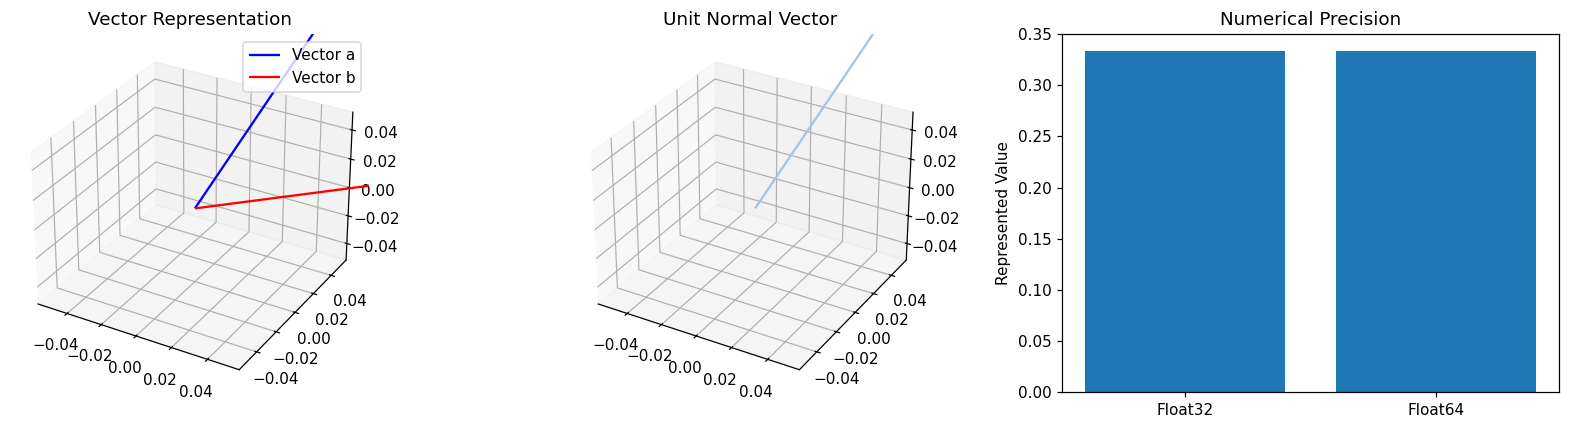


Execution Time: 0.2965044670000907 seconds
Normal RGB: [0.6336 0.7673 0.9009]


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import time

# 1.7 Vector Mathematics
a = np.array([1, 2, 3])
b = np.array([4, 2, 1])

magnitude = np.linalg.norm(a)
dot_product = np.dot(a, b)
cross_product = np.cross(a, b)
unit_vector = a / magnitude

print("Magnitude:", magnitude)
print("Dot Product:", dot_product)
print("Cross Product:", cross_product)

# 1.7.1 Numerical Precision
single = np.float32(1 / 3)
double = np.float64(1 / 3)

print("\nSingle Precision:", single)
print("Double Precision:", double)

# 1.7.2 Debugging and Error Analysis
normal = unit_vector
rgb = (normal + 1) / 2

# 1.7.3 Data Visualisation and Evaluation
fig = plt.figure(figsize=(15, 4))

# Subplot 1: Vector representation
ax1 = fig.add_subplot(131, projection='3d')
ax1.quiver(0, 0, 0, *a, color='blue', label='Vector a')
ax1.quiver(0, 0, 0, *b, color='red', label='Vector b')
ax1.set_title("Vector Representation")
ax1.legend()

# Subplot 2: Normal vector visualisation
ax2 = fig.add_subplot(132, projection='3d')
ax2.quiver(0, 0, 0, *normal, color=rgb)
ax2.set_title("Unit Normal Vector")

# Subplot 3: Precision comparison
ax3 = fig.add_subplot(133)
precision = ['Float32', 'Float64']
values = [single, double]
ax3.bar(precision, values)
ax3.set_title("Numerical Precision")
ax3.set_ylabel("Represented Value")

plt.tight_layout()
plt.show()

# Performance evaluation
start = time.perf_counter()
for _ in range(100000):
    np.dot(a, b)
elapsed = time.perf_counter() - start

print("\nExecution Time:", elapsed, "seconds")
print("Normal RGB:", rgb)